# 01 · Data exploration — synthetic controlled stream

**Goal:** understand the stream before modelling: schema, label balance, feature distributions,
and *where* the ground-truth drift and quality faults are.

> The data is **synthetic** with known drift ground truth (`concept_alpha`). It is used to measure
> detector behaviour, not to claim real-world performance.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from sentinelml.common.config import get_settings
from sentinelml.ingestion.loaders import load_stream

s = get_settings()
df = load_stream("sudden", seed=0)
print(df.shape)
df.head()

(12024, 12)


,timestamp,sensor_a,sensor_b,sensor_c,load_kw,temp_c,region,label,concept_alpha,is_synthetic,batch_id,quality_fault
0,2026-01-01 00:00:00,0.141740,-0.465822,0.253263,77.714565,23.387331,north,1,0.0,True,0,False
1,2026-01-01 00:01:00,-0.199004,-0.290981,0.511125,58.573007,21.007109,east,0,0.0,True,0,False
2,2026-01-01 00:02:00,-0.700635,-0.677605,-1.605340,43.214244,13.378717,east,0,0.0,True,0,False
3,2026-01-01 00:03:00,0.542128,1.020339,1.110502,55.129627,17.947218,east,1,0.0,True,0,False
4,2026-01-01 00:04:00,0.888057,2.622149,0.854993,90.231568,26.026691,west,0,0.0,True,0,False


## Schema & label balance

In [2]:
print(df.dtypes)
print("\nPositive rate overall: %.3f" % df.label.mean())
print("Pre-drift: %.3f | post-drift: %.3f" % (df[df.concept_alpha == 0].label.mean(), df[df.concept_alpha == 1].label.mean()))

timestamp        datetime64[us]
sensor_a                float64
sensor_b                float64
sensor_c                float64
load_kw                 float64
temp_c                  float64
region                   object
label                     int64
concept_alpha           float64
is_synthetic               bool
batch_id                  int64
quality_fault              bool
dtype: object

Positive rate overall: 0.490
Pre-drift: 0.496 | post-drift: 0.484


## Feature distributions before vs after drift

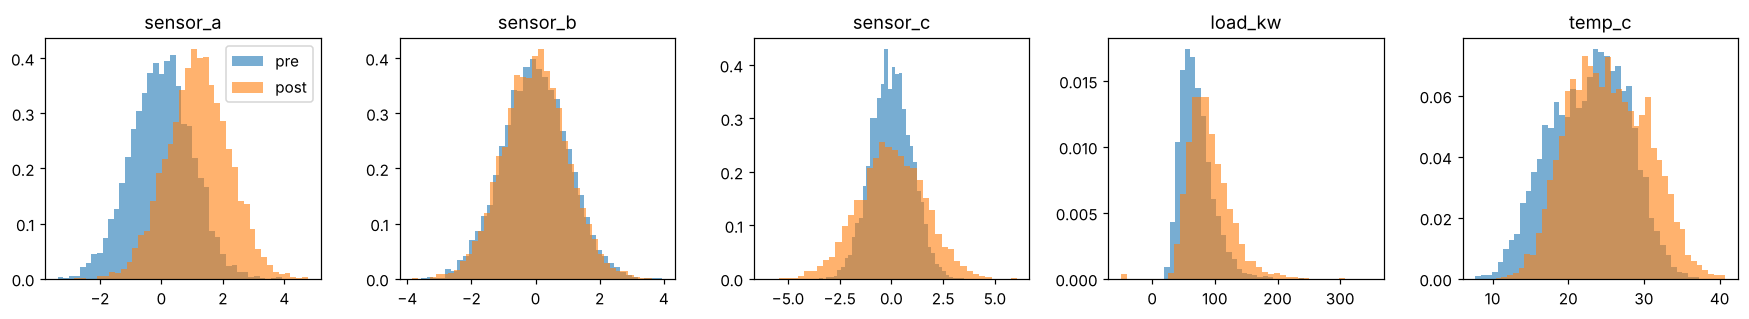

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, f in zip(axes, s.numeric_features):
    clean = df[(df[f].abs() < 500)]
    ax.hist(clean[clean.concept_alpha == 0][f].dropna(), bins=40, alpha=.6, label="pre", density=True)
    ax.hist(clean[clean.concept_alpha == 1][f].dropna(), bins=40, alpha=.6, label="post", density=True)
    ax.set_title(f)
axes[0].legend()
plt.tight_layout()

## Ground truth timeline for all drift types

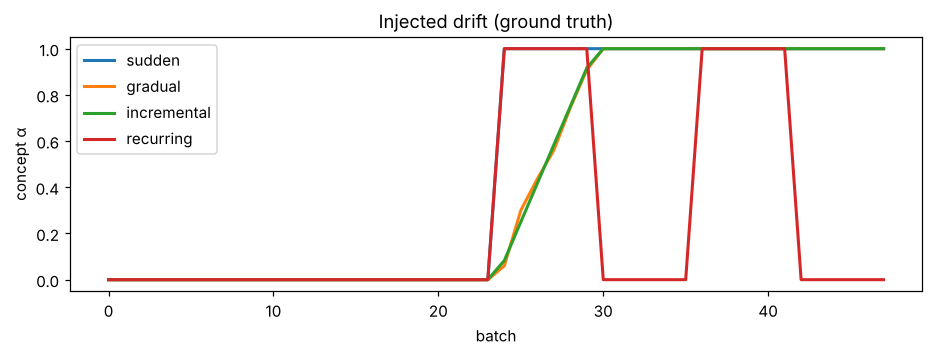

In [4]:
fig, ax = plt.subplots(figsize=(10, 3))
for dt in s.monitoring["experiments"]["drift_types"]:
    d = load_stream(dt, seed=0)
    ax.plot(d.groupby("batch_id").concept_alpha.mean(), label=dt, lw=2)
ax.set(xlabel="batch", ylabel="concept α", title="Injected drift (ground truth)")
ax.legend()

## Injected quality faults

In [5]:
faults = df[df.quality_fault]
print("Faulted batches:", sorted(faults.batch_id.unique()))
print("Null sensor_b:", faults.sensor_b.isna().sum(), "| temp_c=999:", (faults.temp_c == 999).sum(),
      "| unseen regions:", (faults.region == "unknown_site").sum())

Faulted batches: [np.int64(30), np.int64(38)]
Null sensor_b: 77 | temp_c=999: 24 | unseen regions: 30
